# Simple 2 — Tactical Deconfliction Only

Este notebook testa somente o desconflito tático (TD). Dois UAVs recebem planos de voo frontais na mesma altitude. O desconflito estratégico (SD) é desabilitado passando `None` para seus dois algoritmos; internamente, a `Simulation` usa o algoritmo dummy que aprova os planos sem modificá-los.

O Tracking Module prevê o encontro e o TD altera o plano de um dos UAVs durante o voo.

In [81]:
from pathlib import Path
import sys

current_directory = Path.cwd().resolve()
PROJECT_ROOT = next(
    directory
    for directory in (current_directory, *current_directory.parents)
    if (directory / "pyproject.toml").exists()
)
SOURCE_ROOT = PROJECT_ROOT / "src"
for path in (PROJECT_ROOT, SOURCE_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
from IPython.display import Image, display

from gpt.gpt_tactical_conflict_prediction import (
    GPTTacticalConflictPrediction,
)
from gpt.gpt_tactical_deconfliction import GPTTacticalDeconfliction
from gpt.gpt_tracking import GPTTracking
from utm_simulator.airspace import Airspace
from utm_simulator.algorithms.builtins import (
    FirstOrderDynamics,
    PerfectSensor,
    WaypointGuidance,
)
from utm_simulator.domain import FlightPlan, Waypoint
from utm_simulator.simulation import (
    Simulation,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)

OUTPUT_DIRECTORY = PROJECT_ROOT / "gpt" / "outputs"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_PATH = OUTPUT_DIRECTORY / "simple2_td_only.sqlite"

print("Imports concluídos.")

Imports concluídos.


## Planos frontais

Os UAVs percorrem o mesmo eixo em sentidos opostos, ambos a `z = 100`. Sem intervenção, eles alcançariam o centro simultaneamente.

In [82]:
flight_plans = {
    "UAV A": FlightPlan([
        Waypoint(-400, 0, 200, 2),
        Waypoint(400, 0, 200, 30),
    ]),
    "UAV B": FlightPlan([
        Waypoint(400, 0, 200, 2),
        Waypoint(-400, 0, 200, 30),
    ]),
}

flight_plans

{'UAV A': FlightPlan(waypoint_list=[Waypoint(x=-400.0, y=0.0, z=200.0, t=2.0), Waypoint(x=400.0, y=0.0, z=200.0, t=30.0)]),
 'UAV B': FlightPlan(waypoint_list=[Waypoint(x=400.0, y=0.0, z=200.0, t=2.0), Waypoint(x=-400.0, y=0.0, z=200.0, t=30.0)])}

## Configuração da simulação

Os dois parâmetros estratégicos permanecem como `None`, desabilitando o SD. O tracking, o preditor tático e o algoritmo de desconflito tático continuam ativos.

In [83]:
simulation = Simulation(
    airspace=Airspace(),
    # SD desabilitado: o dummy interno somente aprova os planos.
    strategic_conflict_prediction_algorithm=None,
    strategic_deconfliction_algorithm=None,
    # Componentes necessários para o TD.
    tracking_algorithm=GPTTracking(),
    tactical_conflict_prediction_algorithm=(
        GPTTacticalConflictPrediction(
            minimum_horizontal_separation=30,
            minimum_vertical_separation=20,
        )
    ),
    tactical_deconfliction_algorithm=GPTTacticalDeconfliction(
        vertical_maneuver=40,
        resolution_cooldown=8,
    ),
    report_interval=0.5,
    history_window=6,
    prediction_horizon=20,
    prediction_step=0.5,
    flight_update_interval=0.1,
    trajectory_record_interval=0.2,
    dataset_path=DATASET_PATH,
    dataset_flush_interval=5,
    dataset_metadata={"scenario": "simple2_td_only"},
    overwrite_dataset=True,
)

assert simulation.configuration["strategic_deconfliction_enabled"] is False
assert simulation.tactical_module is not None
print("SD habilitado:", simulation.configuration["strategic_deconfliction_enabled"])
print("TD habilitado:", simulation.tactical_module is not None)

SD habilitado: False
TD habilitado: True


In [84]:
for name, flight_plan in flight_plans.items():
    simulation.add_uav(
        name=name,
        flight_plan=flight_plan,
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=20,
            velocity_time_constant=0.2,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0,
            max_speed=20,
        ),
        sensor_model=PerfectSensor(),
        waypoint_acceptance_radius=3,
    )

print("UAVs adicionados:", tuple(simulation.uavs))

UAVs adicionados: ('UAV A', 'UAV B')


## Execução e verificação

Uma versão autorizada é criada quando o plano é aprovado. Portanto, um UAV com duas versões no histórico recebeu uma atualização tática.

In [85]:
result = simulation.run(until=60)
simulation.close()

plan_versions = {
    name: len(history)
    for name, history in result.flight_plan_history.items()
}
tactical_events = [
    event
    for event in result.event_history
    if event.event == "TACTICAL_UPDATES_ISSUED"
]

assert tactical_events, "O TD não emitiu nenhuma atualização."
assert any(count > 1 for count in plan_versions.values())

print("Status final:", {
    name: uav.status.name for name, uav in result.uavs.items()
})
print("Versões autorizadas por UAV:", plan_versions)
print("Intervenções táticas:", len(tactical_events))
for event in tactical_events:
    print(f"t={event.timestamp:.2f}: {event.details}")

Status final: {'UAV A': 'COMPLETED', 'UAV B': 'COMPLETED'}
Versões autorizadas por UAV: {'UAV A': 1, 'UAV B': 2}
Intervenções táticas: 1
t=8.50: {'uavs': ['UAV B']}


In [86]:
from math import dist

states_by_time = {}
for uav_name, history in result.state_history.items():
    for state in history:
        states_by_time.setdefault(round(state.timestamp, 8), {})[uav_name] = state

active_distances = [
    dist(states["UAV A"].position, states["UAV B"].position)
    for states in states_by_time.values()
    if set(states) == set(flight_plans)
    and states["UAV A"].status.name == "ACTIVE"
    and states["UAV B"].status.name == "ACTIVE"
]
minimum_distance = min(active_distances)

print(f"Menor distância 3D durante o voo: {minimum_distance:.2f}")

Menor distância 3D durante o voo: 38.31


## Visualização

A vista XZ evidencia a manobra vertical produzida pelo TD. As linhas de tracking mostram as previsões disponíveis ao longo da execução.

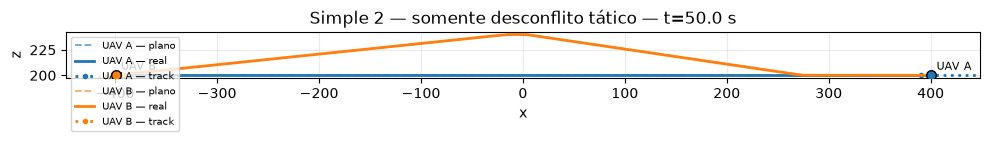

Imagem salva em: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/gpt/outputs/simple2_td_only_xz.png


In [89]:
visualization_config = VisualizationConfig(
    uav_names=("UAV A", "UAV B"),
    view="xz",
    show_real_trajectories=True,
    show_current_positions=True,
    show_tracks=True,
    show_flight_plans=True,
    show_sensor_reports=False,
    show_geofences=False,
    show_wind_zones=False,
    show_obstacles=False,
    start_time=0,
    end_time=50,
    frame_step=0.25,
    title="Simple 2 — somente desconflito tático",
)

snapshot_path = OUTPUT_DIRECTORY / "simple2_td_only_xz.png"
figure = plot_dataset(
    DATASET_PATH,
    visualization_config,
    timestamp=50,
    output_path=snapshot_path,
)
display(figure)
plt.close(figure)
print("Imagem salva em:", snapshot_path)

Animação salva em: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/gpt/outputs/simple2_td_only_xz.gif


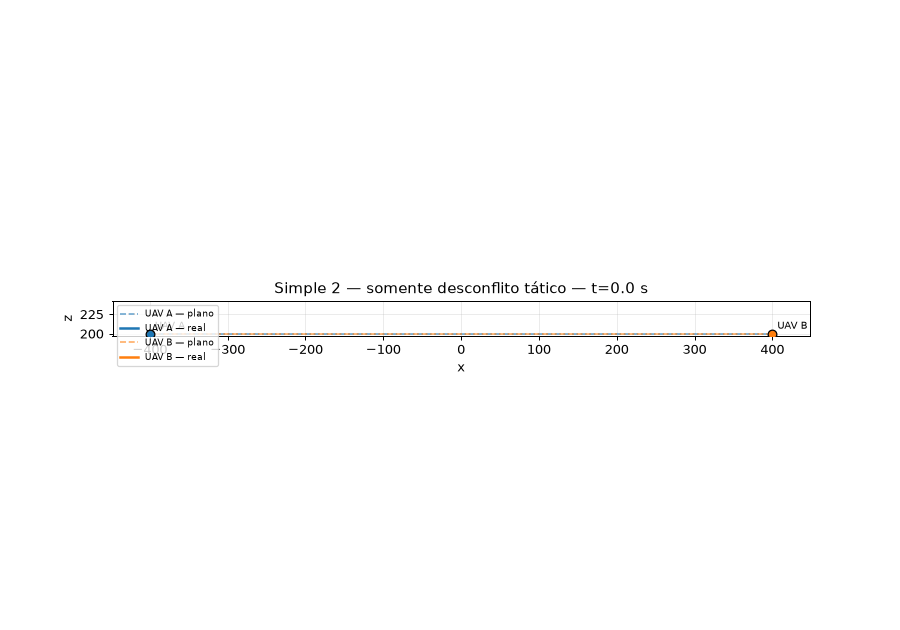

In [90]:
animation_path = OUTPUT_DIRECTORY / "simple2_td_only_xz.gif"
animation = animate_dataset(
    DATASET_PATH,
    visualization_config,
    output_path=animation_path,
    fps=20,
    dpi=90,
)
plt.close(animation._fig)
print("Animação salva em:", animation_path)
display(Image(filename=str(animation_path)))